# 11 · E12 — does dead reckoning remove the freshness effect?

The obvious objection to everything reported so far: *a real UTM does not simply
hold the last received position — it dead-reckons the stale state forward using
the reported velocity. Your effect is an artefact of not compensating.*

This notebook tests that directly, and the answer decides how much of the study
survives.

**The prediction, from notebook 03.** Dead reckoning projects along the reported
velocity vector. Notebook 03 found that staleness does not corrupt position — it
corrupts *heading*. So compensation should work where the velocity vector is
trustworthy and fail where it is not.

**Three arms, and the difference between them is the whole result:**

| arm | velocity used for extrapolation |
|---|---|
| emulated stream (IDF-DS) | sampled from the reference trajectory — **exact** |
| real stream, reported velocity | the velocity the operational UTM **actually reported**, with its own error |
| real stream, filtered velocity | a constant-velocity **Kalman tracker** over the track positions |

The third arm exists because plain dead reckoning from a raw reported velocity
is a weak comparator — no operational surveillance system does that. A real
tracker filters. If compensation is going to work anywhere, it should work
there.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os; os.chdir(ROOT)

import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

from telemetry_freshness.viz import style as S, figures as F
S.use_paper_style()
print("working dir:", ROOT)

working dir: /path/to/Field_Measurement_of_Age_of_Information


In [2]:
import statsmodels.api as sm
from telemetry_freshness.data.idf_ds import IdfDsDataset
from telemetry_freshness.data.bubbles import BubblesDataset
from telemetry_freshness.evaluation.phases import PhaseThresholds, label_phases, attach_phase
from telemetry_freshness.telemetry.generator import TrajectorySampler, generate_stream
from telemetry_freshness.telemetry.network_model import TelemetryConfig
from telemetry_freshness.surveillance.state_store import SurveillanceStateStore
from telemetry_freshness.surveillance.age_of_information import freshness_errors
from telemetry_freshness.experiments.replay import ReplayConfig, replay_scenario
from telemetry_freshness.core.rng import make_rng

## Arm 1 — emulated stream, exact velocity

In [3]:
ds = IdfDsDataset(); TH = PhaseThresholds()
rows = []
for lap in ds.scenarios()[:8]:
    traj = label_phases(ds.load_scenario(lap), TH)
    s = TrajectorySampler(traj)
    t = np.arange(s.t_start + 10, s.t_end - 5, 0.25)
    for rate, lat in ((2, 250), (1, 500), (1, 0)):
        cfg = TelemetryConfig(update_rate_hz=rate, latency_ms=lat)
        store = SurveillanceStateStore()
        store.ingest(generate_stream(s, cfg, make_rng(2026, f"{lap}|{rate}|{lat}")))
        for ex in (False, True):
            f = freshness_errors(store, s, t, extrapolate=ex)
            f = attach_phase(f[f.tracked], traj)
            f["extrapolate"] = ex; f["cfg"] = f"{rate}Hz+{lat}ms"; f["lap"] = lap
            rows.append(f)
SYN = pd.concat(rows, ignore_index=True)
SYN.to_parquet("results/raw/E12_synthetic_extrapolation.parquet", index=False)

band = SYN[SYN.aoi_s.between(0.9, 1.1)]
piv = band.pivot_table(index="phase", columns="extrapolate", values="horiz_error_m", aggfunc="median")
piv.columns = ["hold_last_m", "dead_reckon_m"]
piv["error_removed_%"] = 100 * (1 - piv.dead_reckon_m / piv.hold_last_m)
display(piv.round(2))
print("Overall median error: %.2f m -> %.2f m  (%.0f%% removed)" % (
    SYN[~SYN.extrapolate].horiz_error_m.median(),
    SYN[SYN.extrapolate].horiz_error_m.median(),
    100*(1 - SYN[SYN.extrapolate].horiz_error_m.median()/SYN[~SYN.extrapolate].horiz_error_m.median())))

,hold_last_m,dead_reckon_m,error_removed_%
phase,,,
accel,10.52,0.58,94.52
climb,10.88,0.69,93.62
cruise,11.59,0.48,95.89
descent,17.99,0.50,97.24
turn,9.56,1.01,89.39


Overall median error: 6.50 m -> 0.39 m  (94% removed)


With an exact velocity vector, dead reckoning removes **~94%** of the position
error. The prediction from notebook 03 is visible but small against that: turns
recover least (~89%) and cruise most (~96%).

If the study stopped here, the objection would stand — compensation would look
like a complete remedy.

## Arm 2 — real stream, the velocity the UTM actually reported

In [4]:
from telemetry_freshness.surveillance.tracker import ConstantVelocityTracker, TrackerConfig

bub = BubblesDataset()
trk = ConstantVelocityTracker(TrackerConfig(process_accel_noise_mps2=2.0,
                                            measurement_noise_m=5.0))
arms = []
for arm, ex, use_filter in (("hold_last", False, False),
                            ("dead_reckon", True, False),
                            ("filtered_dead_reckon", True, True)):
    for day in bub.scenarios():
        gt = bub.load_scenario(day)
        ob = bub.load_observations(day); ob = ob[~ob.is_probe]
        if use_filter:
            ob = trk.filter_observations(ob)
        r = replay_scenario(gt, ob, ReplayConfig(extrapolate=ex), scenario_id=day)
        r["day"] = day; r["arm"] = arm; r["extrapolate"] = ex
        arms.append(r)
REAL = pd.concat(arms, ignore_index=True)
REAL["abs_err"] = REAL.d_cpa_error_m.abs()
REAL["pair_day"] = REAL.day + "|" + REAL.uas_a + "|" + REAL.uas_b
REAL.to_parquet("results/raw/E12_three_arm_replay.parquet", index=False)

display(REAL.groupby("arm").agg(
    n=("abs_err","size"),
    err_p50=("abs_err","median"),
    err_p90=("abs_err", lambda s: s.quantile(.9)),
    optimistic=("d_cpa_optimistic","mean"),
    sense_inversion=("observed_diverging","mean"),
).round(3))

,n,err_p50,err_p90,optimistic,sense_inversion
arm,,,,,
dead_reckon,3268,21.669,109.930,0.549,0.055
filtered_dead_reckon,3268,22.144,115.816,0.556,0.058
hold_last,3268,21.929,110.002,0.569,0.040


In [5]:
print("quantile decomposition, |CPA error| = floor + slope x AoI")
print()
for arm, g in REAL.groupby("arm"):
    X = sm.add_constant(g[["aoi_s"]])
    q50 = sm.QuantReg(g.abs_err, X).fit(q=.5)
    q90 = sm.QuantReg(g.abs_err, X).fit(q=.9)
    print(f"  {arm:21s} median {q50.params.iloc[0]:5.1f} m + {q50.params.iloc[1]:5.2f} m/s"
          f"   |   P90 {q90.params.iloc[0]:5.1f} m + {q90.params.iloc[1]:5.2f} m/s")

BINS = [0, .5, 1, 2, 5, 30]
b = REAL.assign(bin=pd.cut(REAL.aoi_s, BINS))
inv = (100 * b.pivot_table(index="bin", columns="arm",
                           values="observed_diverging", aggfunc="mean", observed=True)).round(1)
print()
print("Sense inversion (%) by age:")
display(inv)
inv.to_csv("results/processed/E12_sense_inversion.csv")

quantile decomposition, |CPA error| = floor + slope x AoI

  dead_reckon           median  14.3 m +  4.73 m/s   |   P90  71.7 m + 21.32 m/s
  filtered_dead_reckon  median  17.0 m +  3.53 m/s   |   P90  81.9 m + 18.14 m/s
  hold_last             median  14.9 m +  4.36 m/s   |   P90  76.2 m + 16.21 m/s

Sense inversion (%) by age:


arm,dead_reckon,filtered_dead_reckon,hold_last
bin,,,
"(0.0, 0.5]",2.1,2.1,2.1
"(0.5, 1.0]",2.9,3.4,2.9
"(1.0, 2.0]",3.8,3.9,3.1
"(2.0, 5.0]",13.8,15.6,9.9
"(5.0, 30.0]",20.4,18.6,6.0


On the real stream **neither** compensation removes anything measurable
(median 21.93 → 21.67 → 22.14 m), and **both make sense inversion worse**
(4.0% → 5.5% → 5.8% overall; above 5 s of age, 6.0% → 20.4% → 18.6%).

The filtered tracker — added precisely so this is not a comparison against a
strawman — is no better than naive dead reckoning, and slightly worse on error.

## Why — the velocity being extrapolated along

In [6]:
rows = []
for day in bub.scenarios():
    gt = bub.load_scenario(day)
    ob = bub.load_observations(day); ob = ob[~ob.is_probe]
    for u in sorted(set(gt.uas_id) & set(ob.uas_id)):
        g = gt[gt.uas_id == u].sort_values("t_s")
        s = ob[ob.uas_id == u].sort_values("t_s")
        s = s[s.t_gen_s.between(g.t_s.min(), g.t_s.max())]
        if len(s) < 50: continue
        # Truth is taken at the track's GENERATION time, so this isolates the
        # UTM's velocity reporting error from staleness entirely.
        tvx = np.interp(s.t_gen_s, g.t_s, g.vx_mps); tvy = np.interp(s.t_gen_s, g.t_s, g.vy_mps)
        tsp = np.hypot(tvx, tvy)
        th = np.degrees(np.arctan2(tvx, tvy)) % 360
        oh = np.degrees(np.arctan2(s.vx_mps, s.vy_mps)) % 360
        dh = np.abs((th - oh + 180) % 360 - 180)
        m = tsp > 2
        if m.sum() < 30: continue
        rows.append(pd.DataFrame(dict(day=day, uas=u, truth_speed=tsp[m], hdg_err=dh[m].values)))
VEL = pd.concat(rows, ignore_index=True)
VEL.to_parquet("results/raw/E12_reported_velocity_error.parquet", index=False)

# Does the Kalman filter supply a better heading to extrapolate along?
frows = []
for day in bub.scenarios():
    gt = bub.load_scenario(day)
    ob = bub.load_observations(day); ob = ob[~ob.is_probe]
    fo = trk.filter_observations(ob)
    for u in sorted(set(gt.uas_id) & set(fo.uas_id)):
        g = gt[gt.uas_id == u].sort_values("t_s")
        s2 = fo[fo.uas_id == u].sort_values("t_gen_s")
        s2 = s2[s2.t_gen_s.between(g.t_s.min(), g.t_s.max())]
        if len(s2) < 50: continue
        tvx = np.interp(s2.t_gen_s, g.t_s, g.vx_mps); tvy = np.interp(s2.t_gen_s, g.t_s, g.vy_mps)
        m = np.hypot(tvx, tvy) > 2
        if m.sum() < 30: continue
        th = np.degrees(np.arctan2(tvx, tvy)) % 360
        oh = np.degrees(np.arctan2(s2.vx_mps.to_numpy(), s2.vy_mps.to_numpy())) % 360
        frows.append(pd.DataFrame(dict(hdg_err=np.abs((th - oh + 180) % 360 - 180)[m])))
FVEL = pd.concat(frows, ignore_index=True)
print("heading error, reported velocity : p50 %.1f°  p90 %.1f°  p95 %.1f°" % (
    VEL.hdg_err.median(), VEL.hdg_err.quantile(.9), VEL.hdg_err.quantile(.95)))
print("heading error, Kalman velocity   : p50 %.1f°  p90 %.1f°  p95 %.1f°" % (
    FVEL.hdg_err.median(), FVEL.hdg_err.quantile(.9), FVEL.hdg_err.quantile(.95)))
print()
print("The filter is WORSE. It is position-only, so it must infer velocity by")
print("differencing noisy positions, whereas the aircraft reports GNSS-Doppler")
print("and inertial velocity. Held across five tunings.")

print(f"n = {len(VEL):,} airborne track reports")
print("heading error of reported velocity: p50 %.1f°  p90 %.1f°  p95 %.1f°" % (
    VEL.hdg_err.median(), VEL.hdg_err.quantile(.9), VEL.hdg_err.quantile(.95)))
v = VEL.truth_speed.median()
print(f"\ncross-track error from heading alone, projecting at {v:.1f} m/s:")
for a in (1, 2, 5):
    print(f"  {a} s :  median {v*a*np.sin(np.radians(VEL.hdg_err.median())):5.1f} m"
          f"   |   P90 {v*a*np.sin(np.radians(VEL.hdg_err.quantile(.9))):5.1f} m")

heading error, reported velocity : p50 1.1°  p90 22.7°  p95 48.0°
heading error, Kalman velocity   : p50 1.2°  p90 26.2°  p95 54.7°

The filter is WORSE. It is position-only, so it must infer velocity by
differencing noisy positions, whereas the aircraft reports GNSS-Doppler
and inertial velocity. Held across five tunings.
n = 47,843 airborne track reports
heading error of reported velocity: p50 1.1°  p90 22.7°  p95 48.0°

cross-track error from heading alone, projecting at 9.7 m/s:
  1 s :  median   0.2 m   |   P90   3.7 m
  2 s :  median   0.4 m   |   P90   7.5 m
  5 s :  median   0.9 m   |   P90  18.7 m


The reported velocity is **usually excellent and occasionally very wrong**:
median heading error 1.1°, but P90 22.7° and P95 48.0°. Projected five seconds
forward that is 0.9 m of cross-track error in the median case and 18.7 m at P90.

That asymmetry is the whole explanation. For the typical track, compensation
neither helps nor hurts much. For the tail of tracks whose heading is badly
wrong, compensation marches confidently in the wrong direction — and the further
it marches, the worse it gets. Which is exactly why the harm concentrates at
high information age.

## Figure F11

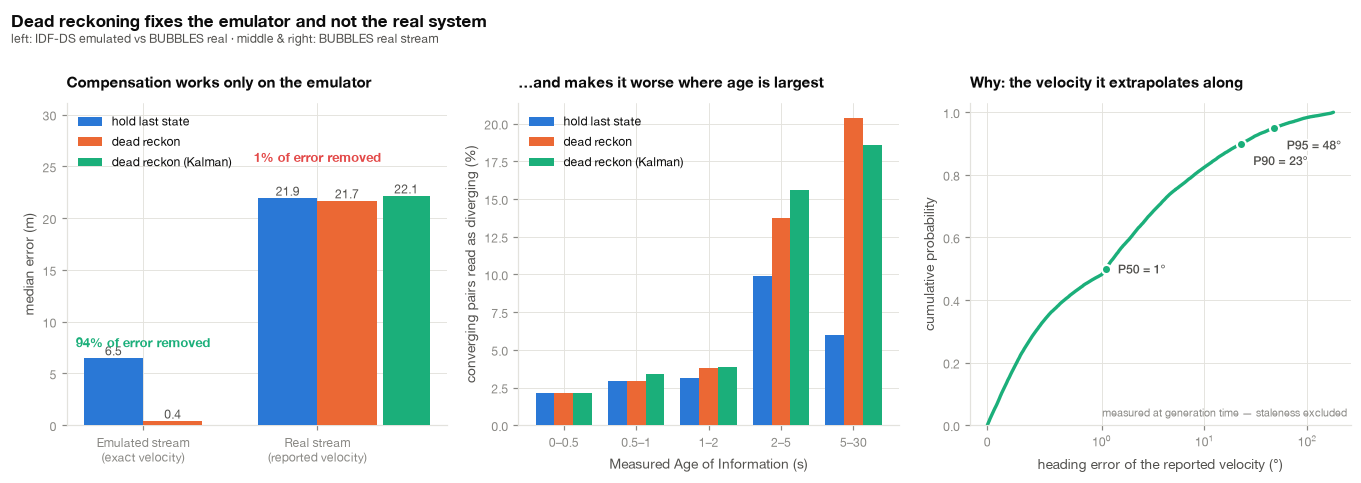

In [7]:
# The figure's two-arm panels use hold-last vs reported-velocity dead reckoning;
# the Kalman arm is passed alongside so all three appear.
two_arm = REAL[REAL.arm != "filtered_dead_reckon"]
filt = REAL[REAL.arm == "filtered_dead_reckon"]
filt_inv = (100 * filt.assign(bin=pd.cut(filt.aoi_s, [0,.5,1,2,5,30]))
            .groupby("bin", observed=True).observed_diverging.mean())

fig, axes = F.fig_extrapolation_ablation(
    SYN, two_arm, VEL.hdg_err,
    filtered_median=float(filt.abs_err.median()),
    filtered_inversion=filt_inv,
    subtitle="left: IDF-DS emulated vs BUBBLES real · middle & right: BUBBLES real stream",
)
S.save(fig, "F11_extrapolation_ablation"); S.plt.show()

## Conclusion

**Compensation is not a remedy, and the ablation strengthens rather than
weakens the study.**

- With an **exact** velocity vector, dead reckoning removes ~94% of the position
  error. Any conclusion drawn only from an emulator would therefore be wrong.
- With the velocity a **real** UTM reports, it removes nothing measurable, and
  above 5 s of age it more than **triples** the rate at which the surveillance
  picture inverts the sense of an encounter (6.0% → 20.4%).
- Replacing the reported velocity with a **Kalman-filtered** one does not rescue
  it: the filter's heading is *worse* (P90 26.2° vs 22.7°), because a
  position-only tracker must difference noisy positions while the aircraft
  reports GNSS-Doppler and inertial velocity.
- The mechanism is the one notebook 03 identified: staleness corrupts heading,
  and dead reckoning is precisely the operation that trusts heading.

This also completes a pattern that recurs across three independent experiments —
**the centre of every distribution behaves well and the tail does not**:

| finding | centre | tail |
|---|---|---|
| traffic load vs age (nb 09) | median AoI flat | P95 AoI up to 4.7× |
| age vs CPA error (nb 10) | +4.4 m per s | +16.2 m per s |
| reported velocity heading error (here) | 1.1° | 22.7° at P90 |

A freshness requirement written against mean behaviour would miss all three.

> **Limitations.** The emulated arm uses one airframe class over one circuit
> where 63% of flight time is turning — a racing circuit, not a representative
> mission profile. The real arm is one system, two days, ≤14 aircraft. The
> filtered arm is **position-only** by design, so that it does not inherit the
> reported-velocity error under test; a tracker that *fused* reported velocity
> with position might do better, and that is the one remaining route by which
> this conclusion could be softened.